# Casus A: Dynamic Modelling (ODEs)

In this notebook we shall explore the concept of dynamic modelling. We have used a collection of different models: Bertalanffy, Exponential, Logistic and Gompertz. With these defined models, we have looked at tumor growth data. To do this, we have applied the ODE solvers scipy and Euler. Next, we applied optimization methods. For this we looked at the methods Hooke & Jeeves and Monte Carlo. Lastly, the data is compared using BIC and AICc.

The used dataset is a simulated dataset which contains different tumors and different treatments. Link: https://github.com/DennisDean/TumorVolumetrics/blob/master/data/synthetic_tumor_data.csv

With this dataset we wanted to explore the growth of different tumors, with a collection of different models. We wanted to find out what the most accurate model, ODE and optimization method is for this dataset.

Research question: Which tumor growth model best describes the observed tumor development?

***

## Data Loading

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from models import TumorGrowthModel, logistic_growth, bertalanffy_growth, gompertz, exponential


# Import modules from your package
from solvers.euler import euler_solver
from solvers.ODE_scipy import solve_ode

We observe the format of the data file by displaying the first lines.

In [36]:
! head /Users/cheyennebrouwer/Documents/26-27/Kwartaal_2/synthetic_tumor_data.csv

Contributor,Arms,Times,Volume,Experiment,Study,ID,Tumor,Disease_Type,Body_Weight,Matched_Controls
Synthetic_Set_1,Treatment_A,0,215.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.23,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,4,298.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.01,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,8,356.421,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.78,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,12,389.234,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.92,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,15,421.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.11,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,18,498.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.03,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,21,567.891,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.87,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,25,712.456,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.93,Treatment_A_Control_1
Synthetic

The data exists of 8 attributes, which have different units. The data is comma separated and contains a header with column names. We define a codebook on basis of the original publication.

In [37]:
codebook = {
    "attribute": [
        "Contributor",
        "Arms",
        "Times",
        "Volume",
        "Experiment",
        "Study",
        "ID",
        "Tumor",
        "Disease_Type",
        "Body_Weight",
        "Matched_Controls"
    ],
    "unit": [
        "-",
        "-",
        "days",
        "mm³",
        "-",
        "-",
        "-",
        "-",
        "-",
        "grams",
        "-"
    ],
    "dtype": [
        "object",
        "object",
        "int64",
        "float64",
        "object",
        "object",
        "object",
        "object",
        "object",
        "float64",
        "object"
    ],
    "description": [
        "Name or identifier of the dataset contributor. Groups related samples or experiments.",
        "Experimental treatment group or control group assigned to the subject.",
        "Time point at which the tumor volume was measured, in days.",
        "Measured tumor volume at the corresponding time point, measured in mm³",
        "Experiment identifier for tracking multiple experiments.",
        "Identifier of the study to which the experiment belongs.",
        "Unique identifier for each tumor sample or PDX (patient-derived xenograft) model.",
        "Name or identifier of the tumor model.",
        "Description or classification of the tumor type.",
        "Body weight of the subject at the corresponding measurement, in grams",
        "Identifier linking the experimental group to its matched control group."
    ]
}
pd.DataFrame(codebook).set_index("attribute")

,unit,dtype,description
attribute,,,
Contributor,-,object,Name or identifier of the dataset contributor....
Arms,-,object,Experimental treatment group or control group ...
Times,days,int64,Time point at which the tumor volume was measu...
Volume,mm³,float64,Measured tumor volume at the corresponding tim...
Experiment,-,object,Experiment identifier for tracking multiple ex...
Study,-,object,Identifier of the study to which the experimen...
ID,-,object,Unique identifier for each tumor sample or PDX...
Tumor,-,object,Name or identifier of the tumor model.
Disease_Type,-,object,Description or classification of the tumor type.


We load the data as follows.

In [38]:
codebook["label"] = [f"{attribute} [{unit}]" for attribute, unit in zip(codebook["attribute"], codebook["unit"])]

data = pd.read_csv("../synthetic_tumor_data.csv", names=codebook["label"], header=0)

data.head()

,Contributor [-],Arms [-],Times [days],Volume [mm³],Experiment [-],Study [-],ID [-],Tumor [-],Disease_Type [-],Body_Weight [grams],Matched_Controls [-]
0,Synthetic_Set_1,Treatment_A,0,215.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.23,Treatment_A_Control_1
1,Synthetic_Set_1,Treatment_A,4,298.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.01,Treatment_A_Control_1
2,Synthetic_Set_1,Treatment_A,8,356.421,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.78,Treatment_A_Control_1
3,Synthetic_Set_1,Treatment_A,12,389.234,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.92,Treatment_A_Control_1
4,Synthetic_Set_1,Treatment_A,15,421.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.11,Treatment_A_Control_1


We verify that all 185 rows and 11 columns have been loaded.

In [39]:
data.shape

(185, 11)

We have made an overview of the dataset.

In [40]:
data.describe(include="all")

,Contributor [-],Arms [-],Times [days],Volume [mm³],Experiment [-],Study [-],ID [-],Tumor [-],Disease_Type [-],Body_Weight [grams],Matched_Controls [-]
count,185,185,185.000000,185.000000,185,185,185,185,185,185.000000,185
unique,1,4,NaN,NaN,1,4,25,4,1,NaN,15
top,Synthetic_Set_1,Control,NaN,NaN,EXP,EXP_1,Model1_101,Model1,Synthetic Models,NaN,Treatment_A_Control_1
freq,185,89,NaN,NaN,185,72,8,72,185,NaN,16
mean,NaN,NaN,11.464865,810.812832,NaN,NaN,NaN,NaN,NaN,15.633622,NaN
std,NaN,NaN,7.617208,722.463116,NaN,NaN,NaN,NaN,NaN,1.108299,NaN
min,NaN,NaN,0.000000,17.591000,NaN,NaN,NaN,NaN,NaN,13.340000,NaN
25%,NaN,NaN,4.000000,340.234000,NaN,NaN,NaN,NaN,NaN,14.870000,NaN
50%,NaN,NaN,12.000000,567.891000,NaN,NaN,NaN,NaN,NaN,15.470000,NaN
75%,NaN,NaN,18.000000,1092.234000,NaN,NaN,NaN,NaN,NaN,16.450000,NaN


We verify there are no missing values.

In [41]:
data.isnull().sum()

Contributor [-]         0
Arms [-]                0
Times [days]            0
Volume [mm³]            0
Experiment [-]          0
Study [-]               0
ID [-]                  0
Tumor [-]               0
Disease_Type [-]        0
Body_Weight [grams]     0
Matched_Controls [-]    0
dtype: int64

#### Conclusion

The data has been loaded correctly and is suitable to be used in further processing.

***

## Data Visualisation

To explore the correlation between attributes, we deploy scatterplots and calculate correlations.

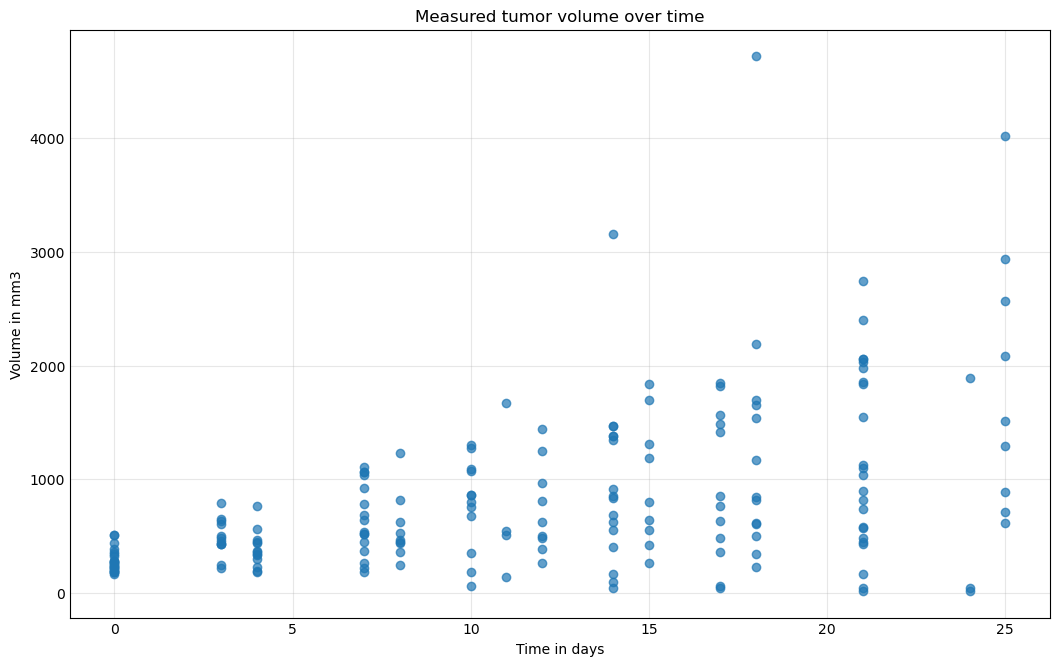

In [44]:
plt.figure(figsize=(10,6))

plt.scatter(
    data["Times [days]"],
    data["Volume [mm³]"],
    alpha=0.7
)

plt.xlabel("Time in days")
plt.ylabel("Volume in mm3")
plt.title("Measured tumor volume over time")

plt.grid(alpha=0.3)
plt.show()

In the violinplot below, we show the distribution of tumor volume per treatment. This is the beginning volume, before any predictions have been done.

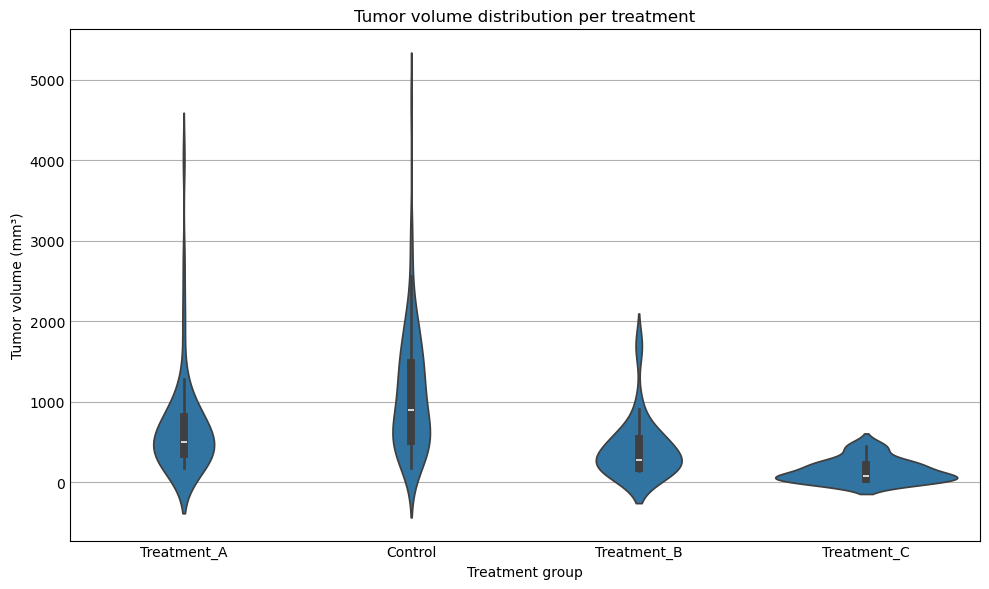

In [49]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=data,
    x="Arms [-]",
    y="Volume [mm³]",
    inner="box"
)

plt.xlabel("Treatment group")
plt.ylabel("Tumor volume (mm³)")
plt.title("Tumor volume distribution per treatment")

plt.tight_layout()
plt.show()

The boxplot below shows the distribution of tumor volumes.

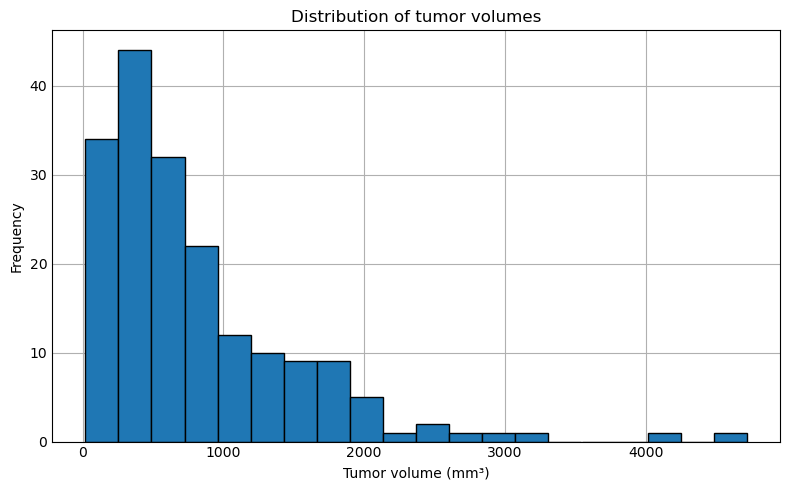

In [50]:
plt.figure(figsize=(8, 5))

plt.hist(data["Volume [mm³]"], bins=20, edgecolor="black")

plt.xlabel("Tumor volume (mm³)")
plt.ylabel("Frequency")
plt.title("Distribution of tumor volumes")

plt.tight_layout()
plt.show()

Conclusion: The frequency of tumor volume per mm3 is the highest below 1000mm3.

The boxplot below shows the distribution and outliers of tumor volumes. This is useful because it provides insight into the variation in tumor sizes, helps identify unusually large or small tumor volumes, and allows us to assess the spread and median of the measurements.

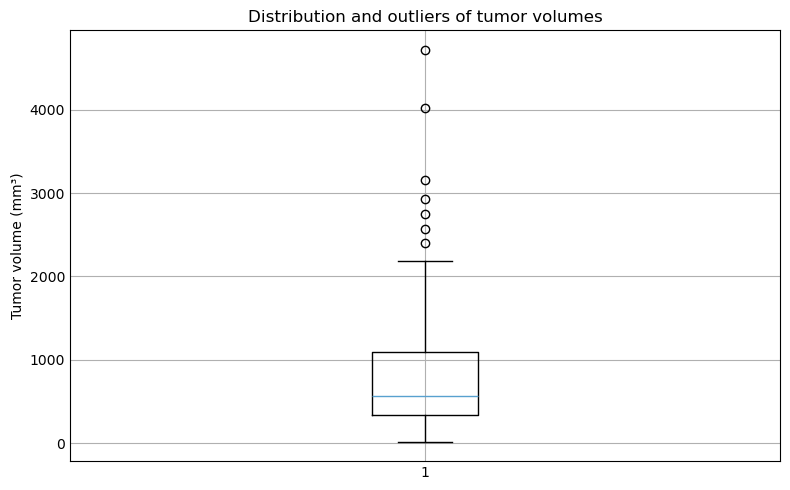

In [51]:
plt.figure(figsize=(8, 5))

plt.boxplot(data["Volume [mm³]"])

plt.ylabel("Tumor volume (mm³)")
plt.title("Distribution and outliers of tumor volumes")

plt.tight_layout()
plt.show()

Conclusion: The median tumor volume is approximately 550 mm³, meaning that half of the measurements are below this value and half are above it. The middle 50% of tumor volumes range from approximately 330 to 1,100 mm³. The distribution is positively skewed, as several unusually large tumor volumes appear above the upper whisker. These outliers reach values of over 4,000 mm³, indicating considerable variation in tumor size.

***
## Applying Tumor Growth Models

In this section, four different tumor growth models are applied to the dataset. These models describe tumor growth in different ways and allow us to compare their ability to represent the observed tumor volume over time.

In [54]:
tumor_id = "Model1_101"

tumor_data = data[data["ID [-]"] == tumor_id].copy()
tumor_data = tumor_data.sort_values("Times [days]")

times = tumor_data["Times [days]"].to_numpy()
volumes = tumor_data["Volume [mm³]"].to_numpy()

print(f"Number of measurements: {len(times)}")
print(f"Time range: {times.min()} - {times.max()} days")
print(f"Initial tumor volume: {volumes[0]:.2f} mm³")

Number of measurements: 8
Time range: 0 - 25 days
Initial tumor volume: 215.34 mm³


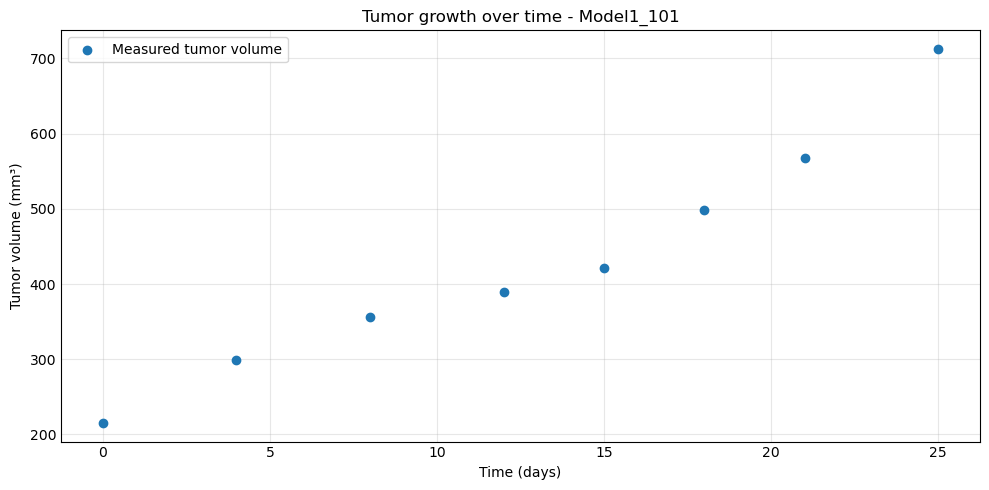

In [55]:
plt.figure(figsize=(10, 5))

plt.scatter(times, volumes, label="Measured tumor volume")

plt.xlabel("Time (days)")
plt.ylabel("Tumor volume (mm³)")
plt.title(f"Tumor growth over time - {tumor_id}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Conclusion: The startvolume of the tumor lies around 215mm3. The tumorvolume increases during the measurement period. On day 25 the tumorvolume is about 715mm3. The growth does not appear to be linear, but has a slight curve.

## Initialising the growth models

In this step, four different tumor growth models are initialized: Logistic, Von Bertalanffy, Exponential and Gompertz. Each model is assigned an initial set of parameters. These models will be used to simulate tumor growth and compare their predictions with the measured tumor volumes. The initial parameters will later be optimized to improve the accuracy of each model.

In [64]:
models = {
    "Logistic": TumorGrowthModel(
        "Logistic", logistic_growth, {"r": 0.2, "K": 1000}
    ),
    "Von Bertalanffy": TumorGrowthModel(
        "Von Bertalanffy", bertalanffy_growth, {"a": 0.5, "b": 0.1}
    ),
    "Exponential": TumorGrowthModel(
        "Exponential", exponential, {"c": 0.2}
    ),
    "Gompertz": TumorGrowthModel(
        "Gompertz", gompertz, {"c": 0.2, "V_max": 1000}
    )
}

## Simulating tumor growth using SciPy

In this step, the SciPy ODE solver is used to simulate tumor growth for each of the four models. The initial tumor volume and measurement time points are used as input. The resulting simulations provide predicted tumor volumes that can be compared with the actual measurements.

In [65]:
# Create a time array for the simulations
t_values = np.linspace(times[0], times[-1], 200)

# Store the simulation results
scipy_results = {}

# Simulate each model
for model_name, model in models.items():
    predicted_volumes = solve_ode(
        model,
        t_values,
        volumes[0]
    )

    scipy_results[model_name] = predicted_volumes

The simulated tumor growth curves are plotted together with the measured tumor volumes. This visualization allows us to compare how well each growth model describes the observed tumor growth and identify differences between their predictions.

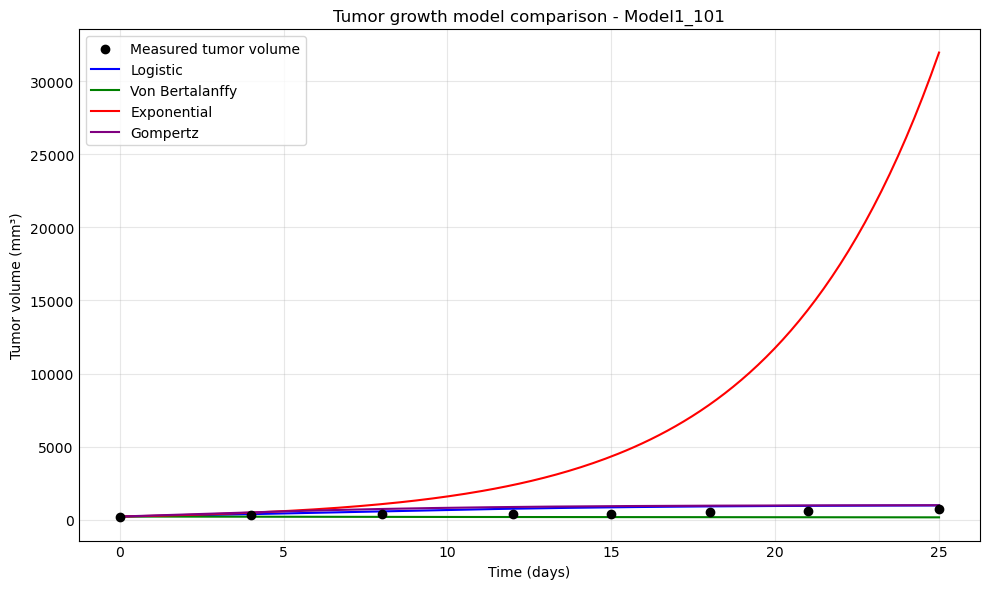

In [67]:
plt.figure(figsize=(10, 6))

# Define colors for each model
model_colors = {
    "Logistic": "blue",
    "Von Bertalanffy": "green",
    "Exponential": "red",
    "Gompertz": "purple"
}

# Plot measured tumor volumes
plt.scatter(
    times,
    volumes,
    color="black",
    label="Measured tumor volume",
    zorder=5
)

# Plot each model with its own color
for model_name, predicted_volumes in scipy_results.items():
    plt.plot(
        t_values,
        predicted_volumes,
        label=model_name,
        color=model_colors[model_name]
    )

plt.xlabel("Time (days)")
plt.ylabel("Tumor volume (mm³)")
plt.title("Tumor growth model comparison - Model1_101")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In this step, the Euler method is used to simulate tumor growth for all four models. Unlike the SciPy solver, the Euler method approximates the solution using fixed time steps. The results can be compared with the measured tumor volumes and the simulations obtained using SciPy.

In [69]:
# Set the time step
dt = 0.1

# Store Euler simulation results
euler_results = {}

# Simulate each model
for model_name, model in models.items():
    calculated_times, calculated_volumes = euler_solver(
        model,
        (times[0], times[-1]),
        volumes[0],
        dt
    )

    euler_results[model_name] = (
        calculated_times,
        calculated_volumes
    )

The Euler and SciPy solvers are compared by plotting their predicted tumor growth curves alongside the measured data. This allows us to evaluate differences between the numerical methods and their ability to reproduce the observed tumor growth.

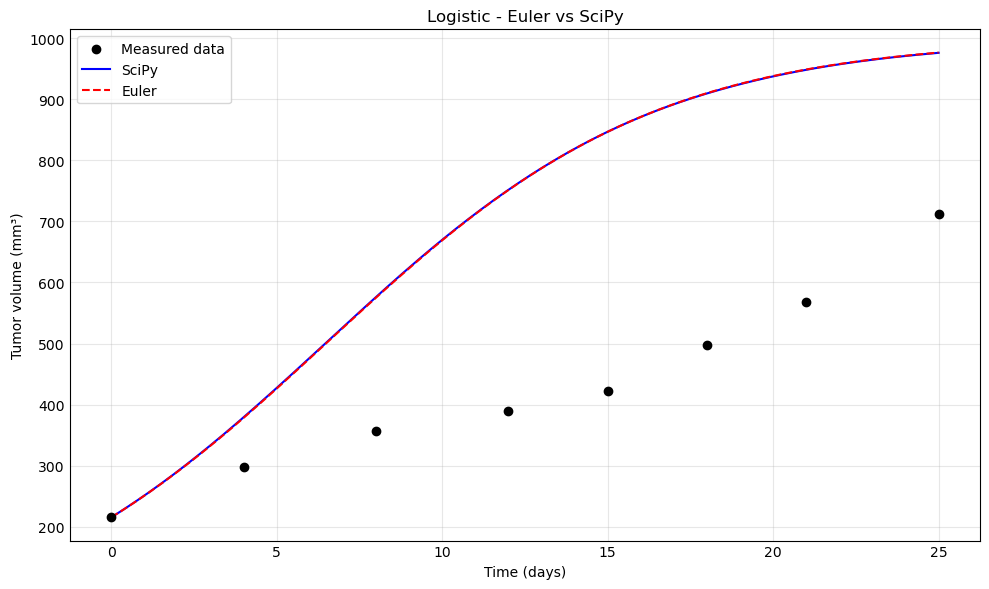

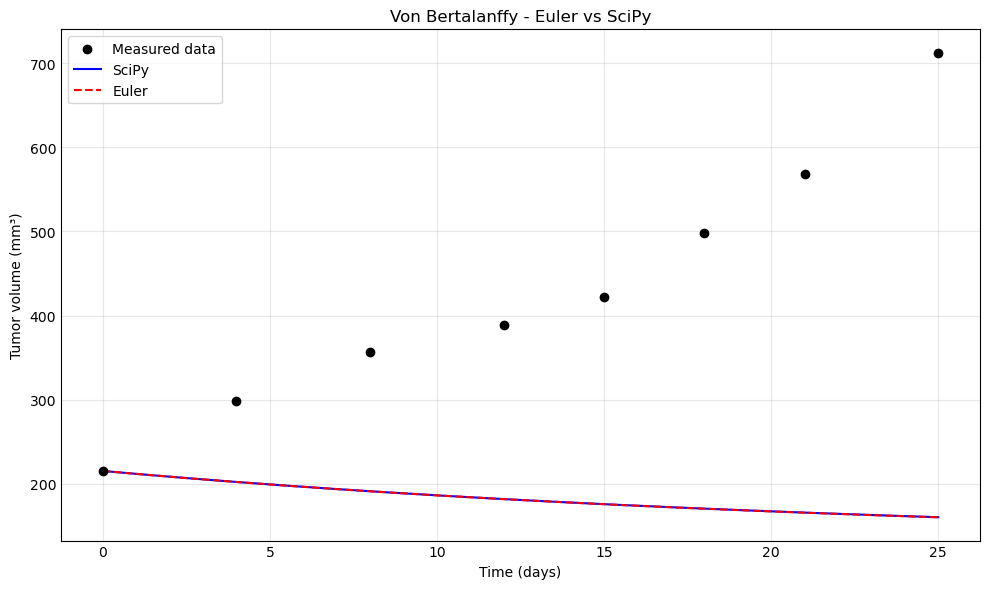

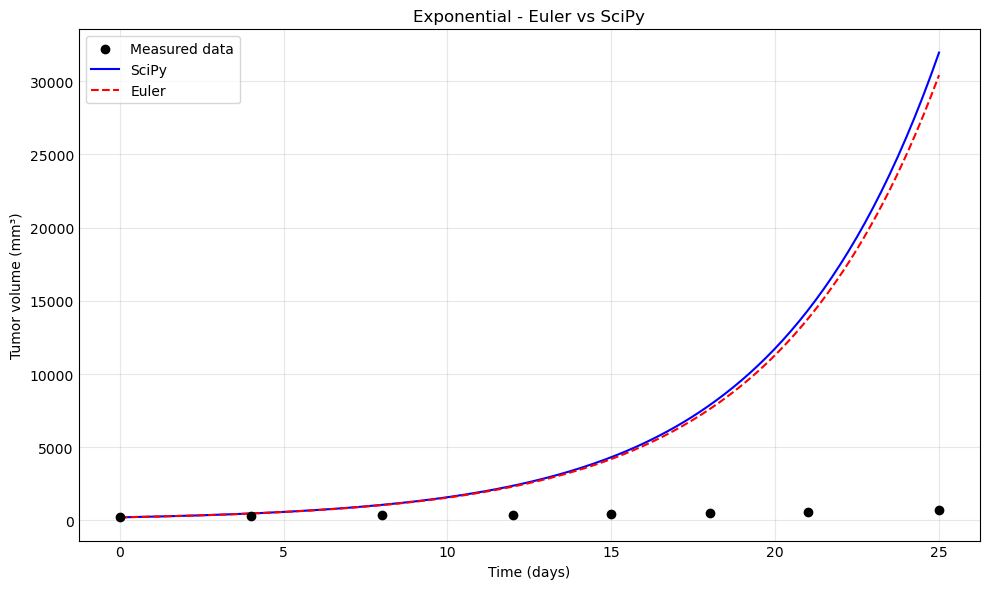

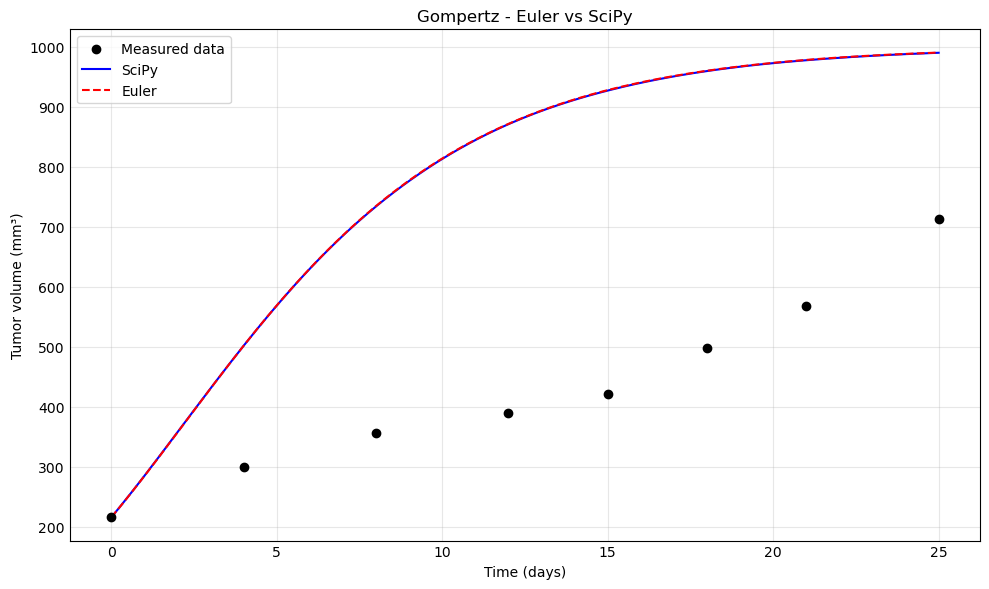

In [70]:
for model_name in models:

    plt.figure(figsize=(10, 6))

    # Measured data
    plt.scatter(
        times, volumes,
        color="black",
        label="Measured data",
        zorder=5
    )

    # SciPy
    plt.plot(
        t_values,
        scipy_results[model_name],
        label="SciPy",
        color="blue"
    )

    # Euler
    euler_times, euler_volumes = euler_results[model_name]

    plt.plot(
        euler_times,
        euler_volumes,
        label="Euler",
        color="red",
        linestyle="--"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Tumor volume (mm³)")
    plt.title(f"{model_name} - Euler vs SciPy")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Conclusion: Comparison of the four tumor growth models

The four models produce different predictions of tumor growth. The exponential model shows extremely rapid growth and greatly overestimates the measured tumor volumes. The Von Bertalanffy model predicts a decrease in tumor volume, which does not correspond to the observed increase.

The Logistic and Gompertz models both predict growth towards a maximum tumor volume of approximately 1000 mm³. However, they also overestimate the measured tumor volumes, particularly towards the end of the observation period.

Furthermore, the Euler and SciPy curves almost completely overlap for all four models. This indicates that both numerical methods produce very similar results with the current settings. The differences between the predictions and the measured data are therefore mainly related to the models and their initial parameter values, rather than the numerical solvers.

Overall, none of the four models accurately describes the measured tumor growth using the current parameter values. Parameter optimization is needed to improve the fit and determine which model best represents the observed data.

### Testing the error calculation

Before performing parameter optimization, the error calculation is tested for all four tumor growth models using both numerical solvers. The Mean Squared Error (MSE) is used to measure the difference between the predicted and measured tumor volumes. A lower MSE indicates a better fit.

In [71]:
from metrics.calculate_error import calculate_error
from solvers.euler import euler_solver
from solvers.ODE_scipy import solve_ode

for model_name, model in models.items():
    print(f"\n{model_name}")

    for solver in [euler_solver, solve_ode]:
        error = calculate_error(
            model,
            solver,
            times,
            volumes,
            model.parameters
        )

        print(f"{solver.__name__}: MSE = {error:.2f}")


Logistic
euler_solver: MSE = 93815.17
solve_ode: MSE = 93804.19

Von Bertalanffy
euler_solver: MSE = 89273.75
solve_ode: MSE = 89231.02

Exponential
euler_solver: MSE = 140762685.96
solve_ode: MSE = 155085780.91

Gompertz
euler_solver: MSE = 141275.10
solve_ode: MSE = 140921.29


### Conclusion: Initial MSE comparison

The initial MSE values show that the Von Bertalanffy model provides the best fit to the measured tumor growth data, with the lowest MSE for both numerical solvers. The Logistic and Gompertz models show higher errors, while the Exponential model performs considerably worse.

The Euler and SciPy solvers produce similar MSE values for most models, indicating that the numerical method has a relatively small influence on the calculated error.

These results are based on the initial model parameters. Parameter optimization is therefore required to determine whether the models can achieve a better fit to the measured data.

### Testing the Hooke-Jeeves optimization

The Hooke-Jeeves method is used to optimize the parameters of the tumor growth models by minimizing the Mean Squared Error (MSE). The optimization starts with the initial parameter values and adjusts them to find a combination that better fits the measured tumor volumes.

In [72]:
from optimization.hooke_jeeves import hooke_jeeves

model = models["Von Bertalanffy"]

optimized_parameters, optimized_mse = hooke_jeeves(
    model,
    solve_ode,
    times,
    volumes
)

print("Optimized parameters:", optimized_parameters)
print("Initial MSE:", calculate_error(
    model, solve_ode, times, volumes, model.parameters
))
print("Optimized MSE:", optimized_mse)

Optimized parameters: {'a': 0.764409600000013, 'b': 0.059175680000000494}
Initial MSE: 89231.02429275624
Optimized MSE: 932.5825740196274


### Results of Hooke-Jeeves optimization

The Hooke-Jeeves optimization significantly improved the fit of the Von Bertalanffy model to the measured tumor growth data.

The initial MSE of 89,231.02 decreased to 932.58 after optimization, representing a reduction of approximately 98.95%.

The optimized parameters were a = 0.76441 and b = 0.05918, compared to the initial values of a = 0.5 and b = 0.1.

This demonstrates that parameter optimization can substantially improve the model's ability to describe the observed tumor growth.

In [73]:
hooke_jeeves_results = {}

for model_name, model in models.items():
    for solver in [euler_solver, solve_ode]:

        parameters, error = hooke_jeeves(
            model,
            solver,
            times,
            volumes
        )

        hooke_jeeves_results[(model_name, solver.__name__)] = {
            "parameters": parameters,
            "MSE": error
        }

        print(f"\n{model_name} - {solver.__name__}")
        print("Parameters:", parameters)
        print("MSE:", error)


Logistic - euler_solver
Parameters: {'r': 0.07367679999998361, 'K': 1101.2611532799353}
MSE: 844.4004741244132

Logistic - solve_ode
Parameters: {'r': 0.07357055999998367, 'K': 1101.208556799935}
MSE: 846.8192796096953

Von Bertalanffy - euler_solver
Parameters: {'a': 0.764017920000013, 'b': 0.05909248000000048}
MSE: 930.3093366178726

Von Bertalanffy - solve_ode
Parameters: {'a': 0.764409600000013, 'b': 0.059175680000000494}
MSE: 932.5825740196274

Exponential - euler_solver
Parameters: {'c': 0.04746752000000001}
MSE: 488.5326945935275

Exponential - solve_ode
Parameters: {'c': 0.047354880000000016}
MSE: 488.36387190340406

Gompertz - euler_solver
Parameters: {'c': 0.04555648000000138, 'V_max': 1073.2628441599575}
MSE: 1325.375803923757

Gompertz - solve_ode
Parameters: {'c': 0.04552960000000139, 'V_max': 1073.6760255999577}
MSE: 1327.195044456635


### Results of Hooke-Jeeves optimization

The Hooke-Jeeves optimization improved the fit of all four tumor growth models considerably.

The Exponential model achieved the lowest MSE, with values of 488.53 for Euler and 488.36 for SciPy. This makes it the best-performing model after optimization.

The Logistic model achieved the second-lowest MSE, followed by the Von Bertalanffy model. The Gompertz model had the highest MSE after optimization.

The results also show that Euler and SciPy produce very similar MSE values for all four models. This suggests that the choice of numerical solver has little influence on the optimization results in this experiment.

Overall, parameter optimization significantly improved the model fits and changed the ranking of the models compared to their initial performance.

### Monte Carlo optimization

The Monte Carlo method is used to optimize the parameters of the four tumor growth models. Random parameter values are generated within predefined parameter bounds. Each parameter combination is evaluated using the Mean Squared Error (MSE). The combination with the lowest MSE is retained as the best result.

In [74]:
from optimization.monte_carlo import monte_carlo

monte_carlo_results = {}

for model_name, model in models.items():
    for solver in [euler_solver, solve_ode]:

        parameters, error = monte_carlo(
            model,
            solver,
            times,
            volumes,
            iterations=1000
        )

        monte_carlo_results[(model_name, solver.__name__)] = {
            "parameters": parameters,
            "MSE": error
        }

        print(f"\n{model_name} - {solver.__name__}")
        print("Parameters:", parameters)
        print("MSE:", error)


Logistic - euler_solver
Parameters: {'r': 0.05655830574177648, 'K': 2367.3140217938476}
MSE: 516.9494221341208

Logistic - solve_ode
Parameters: {'r': 0.057912670674805405, 'K': 2150.5351370861154}
MSE: 534.2160031627579

Von Bertalanffy - euler_solver
Parameters: {'a': 0.5045046068902381, 'b': 0.02236487936348838}
MSE: 676.2382011543398


/Users/cheyennebrouwer/Documents/26-27/Kwartaal_2/Casus_Dynamic-Modelling/models/bertalanffy_model.py:15: RuntimeWarning: invalid value encountered in scalar power
  return a * V ** (2/3) - b * V



Von Bertalanffy - solve_ode
Parameters: {'a': 0.6901163596660354, 'b': 0.051108028724433756}
MSE: 1040.9639200120191

Exponential - euler_solver
Parameters: {'c': 0.04747158845109222}
MSE: 488.5338607953044

Exponential - solve_ode
Parameters: {'c': 0.04777757222437148}
MSE: 502.1823457611922

Gompertz - euler_solver
Parameters: {'c': 0.03730754605264194, 'V_max': 1316.0354069746877}
MSE: 1057.983013624069

Gompertz - solve_ode
Parameters: {'c': 0.02514958752840437, 'V_max': 2657.292242887031}
MSE: 923.9916655663667


### Comparison of Hooke-Jeeves and Monte Carlo optimization

Both optimization methods improved the fit of the tumor growth models compared to their initial parameter values.

Monte Carlo achieved lower MSE values for the Logistic, Von Bertalanffy and Gompertz models. Hooke-Jeeves performed slightly better for the Exponential model, achieving the lowest overall MSE of 488.36 using the SciPy solver.

The results show that Monte Carlo can be effective at finding suitable parameter combinations through random sampling. However, its results depend on the randomly generated parameter values and the number of iterations. Hooke-Jeeves follows a systematic search strategy and achieved a slightly better result for the Exponential model.

The comparison also shows that the choice of numerical solver can influence the optimization results, particularly for the Von Bertalanffy model.

Overall, Monte Carlo performed better for three out of four models, while Hooke-Jeeves achieved the best individual result.

### Visualizing the optimized tumor growth models

In this step, the optimized parameters obtained from Hooke-Jeeves and Monte Carlo are compared. For each tumor growth model, the parameter combination with the lowest MSE is selected. The corresponding numerical solver is then used to simulate tumor growth.

The optimized predictions are plotted alongside the measured tumor volumes to visually evaluate how well each model describes the observed data.

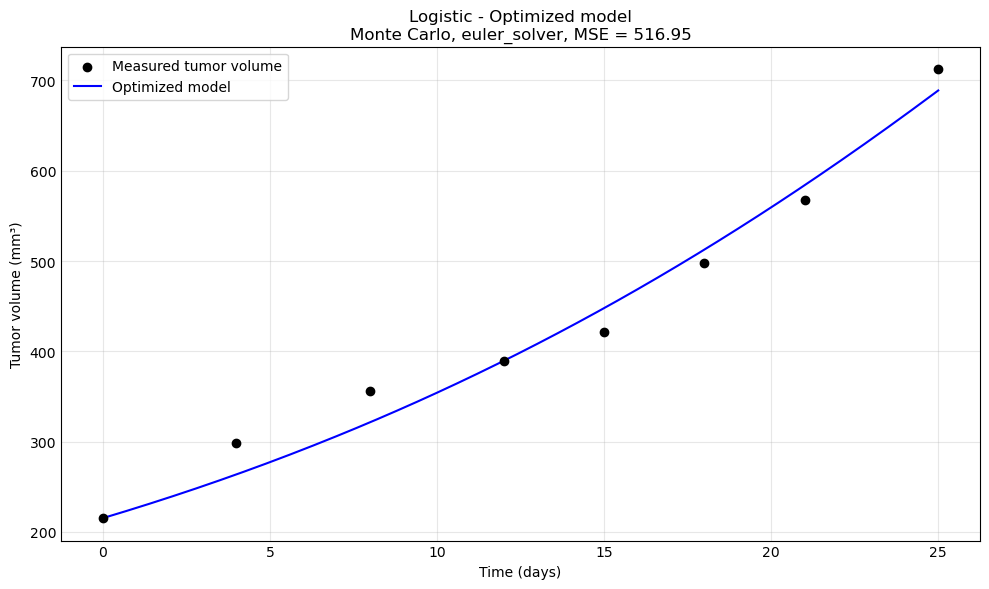


Logistic
Optimization method: Monte Carlo
Solver: euler_solver
Parameters: {'r': 0.05655830574177648, 'K': 2367.3140217938476}
MSE: 516.9494221341208


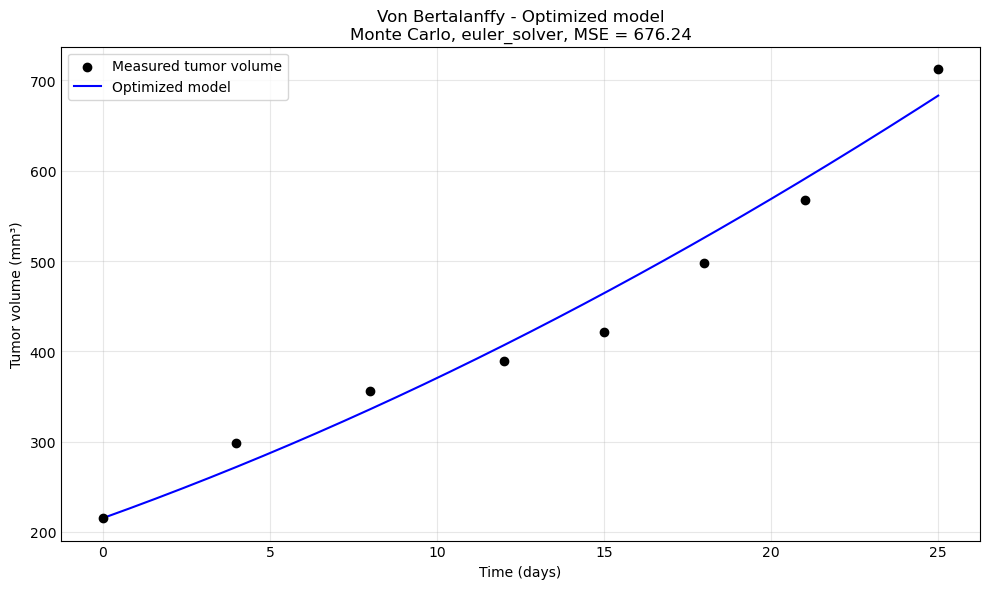


Von Bertalanffy
Optimization method: Monte Carlo
Solver: euler_solver
Parameters: {'a': 0.5045046068902381, 'b': 0.02236487936348838}
MSE: 676.2382011543398


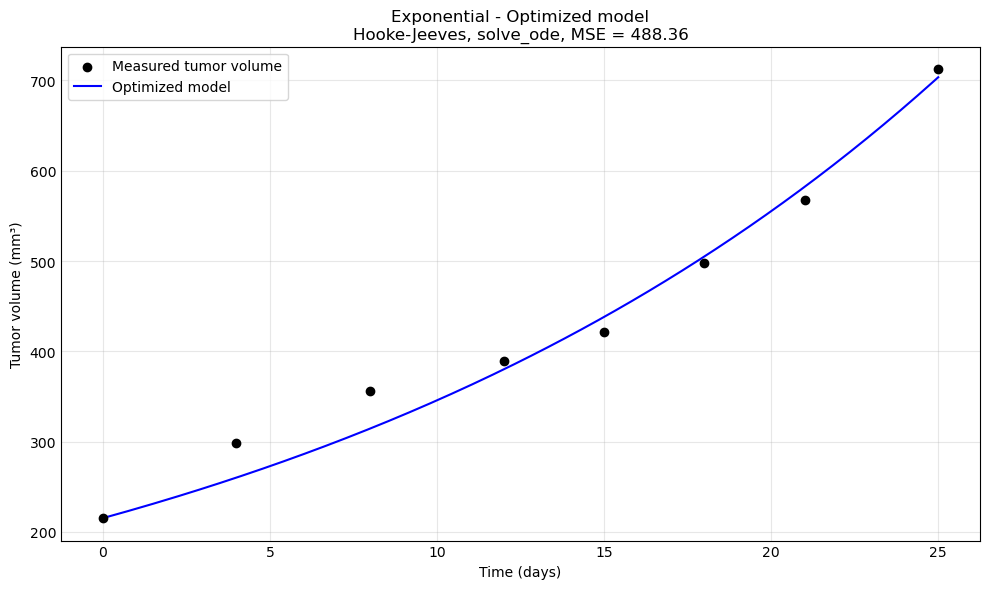


Exponential
Optimization method: Hooke-Jeeves
Solver: solve_ode
Parameters: {'c': 0.047354880000000016}
MSE: 488.36387190340406


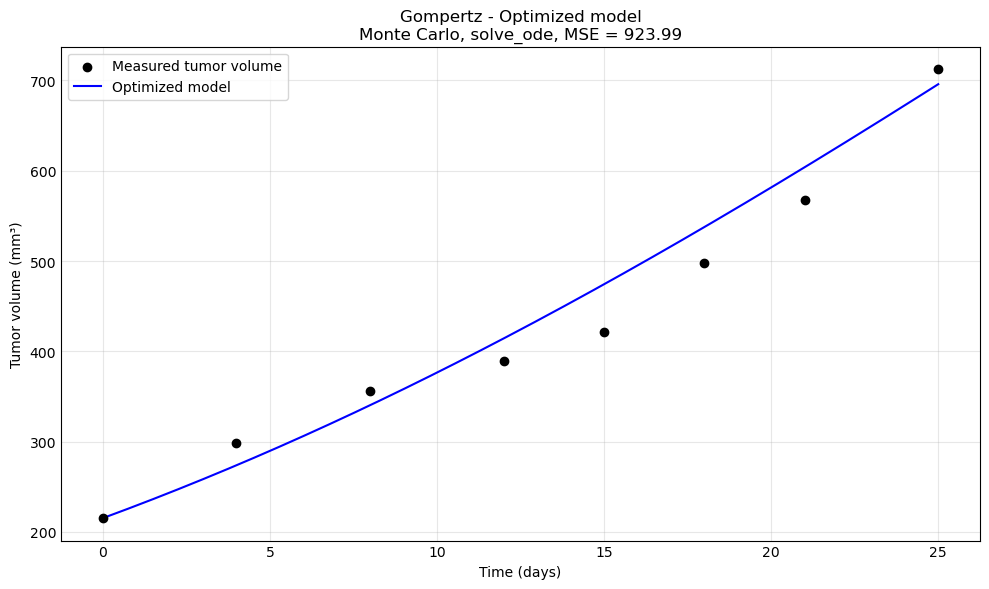


Gompertz
Optimization method: Monte Carlo
Solver: solve_ode
Parameters: {'c': 0.02514958752840437, 'V_max': 2657.292242887031}
MSE: 923.9916655663667


In [75]:
import matplotlib.pyplot as plt

optimized_results = {}

for model_name, model in models.items():

    candidates = {}

    # Add Hooke-Jeeves results
    for solver_name in ["euler_solver", "solve_ode"]:
        result = hooke_jeeves_results[(model_name, solver_name)]
        candidates[("Hooke-Jeeves", solver_name)] = result

    # Add Monte Carlo results
    for solver_name in ["euler_solver", "solve_ode"]:
        result = monte_carlo_results[(model_name, solver_name)]
        candidates[("Monte Carlo", solver_name)] = result

    # Select the result with the lowest MSE
    best_method, best_solver = min(
        candidates,
        key=lambda key: candidates[key]["MSE"]
    )

    best_result = candidates[(best_method, best_solver)]
    best_parameters = best_result["parameters"]
    best_mse = best_result["MSE"]

    # Create model with optimized parameters
    optimized_model = TumorGrowthModel(
        model.name,
        model.function,
        best_parameters
    )

    # Simulate using the selected solver
    if best_solver == "euler_solver":
        predicted_times, predicted_volumes = euler_solver(
            optimized_model,
            (times[0], times[-1]),
            volumes[0],
            0.1
        )
    else:
        predicted_times = t_values
        predicted_volumes = solve_ode(
            optimized_model,
            t_values,
            volumes[0]
        )

    optimized_results[model_name] = {
        "method": best_method,
        "solver": best_solver,
        "parameters": best_parameters,
        "MSE": best_mse
    }

    # Plot results
    plt.figure(figsize=(10, 6))

    plt.scatter(
        times,
        volumes,
        color="black",
        label="Measured tumor volume",
        zorder=5
    )

    plt.plot(
        predicted_times,
        predicted_volumes,
        color="blue",
        label="Optimized model"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Tumor volume (mm³)")
    plt.title(
        f"{model_name} - Optimized model\n"
        f"{best_method}, {best_solver}, MSE = {best_mse:.2f}"
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\n{model_name}")
    print("Optimization method:", best_method)
    print("Solver:", best_solver)
    print("Parameters:", best_parameters)
    print("MSE:", best_mse)

### Visual comparison of the optimized models

The optimized models show a considerable improvement compared to the initial simulations. All four models now follow the general increasing trend of the measured tumor volumes.

The Exponential model provides the best fit, with the lowest MSE of 488.36. Its predicted curve follows the measured data closely throughout the observation period. The Logistic model also provides a good fit, with an MSE of 516.95.

The Von Bertalanffy model follows the general growth trend but shows larger deviations from some measured values. The Gompertz model has the highest MSE and shows the largest overall deviations.

Based on both the visual comparison and the MSE values, the Exponential model performs best for this dataset, followed closely by the Logistic model.

### Conclusion

After optimizing the parameters of the four tumor growth models using the Hooke-Jeeves and Monte Carlo optimization methods, the models were compared using their Mean Squared Error (MSE).

The exponential model achieved the lowest MSE of 488.36, indicating the best fit to the measured tumor volume data. The logistic model performed similarly, with an MSE of 516.95. The Von Bertalanffy model showed a less accurate fit, with an MSE of 676.24, while the Gompertz model had the highest MSE of 923.99.

The results show that the exponential model provides the best description of the observed tumor growth for the selected dataset. However, the logistic model also provides a reasonable approximation. The Von Bertalanffy and Gompertz models show larger deviations from the measured data.

Furthermore, the Euler and SciPy solvers produced very similar results in the earlier simulations. This suggests that both numerical methods can approximate the tumor growth models effectively for the selected time interval. Small differences in MSE can occur due to numerical approximation and differences in optimization results.

Overall, the exponential model combined with parameter optimization provides the most accurate fit for this particular tumor dataset.